In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("04_online_retail.csv",encoding="latin-1")

In [ ]:
df.describe()

,Quantity,UnitPrice,CustomerID,invoice_year,invoice_month
count,25000.000000,25000.000000,18700.000000,25000.000000,25000.00000
mean,9.505600,5.111353,15257.567166,2010.921200,7.55692
std,43.222214,120.066142,1713.557230,0.269432,3.51160
min,-2376.000000,0.000000,12347.000000,2010.000000,1.00000
25%,1.000000,1.250000,13899.750000,2011.000000,5.00000
50%,3.000000,2.080000,15078.000000,2011.000000,8.00000
75%,10.000000,4.130000,16764.000000,2011.000000,11.00000
max,2880.000000,13541.330000,18287.000000,2011.000000,12.00000


In [ ]:
df_cleaned=df.dropna(subset=['CustomerID'])

In [ ]:
returns=df[df['Quantity']<0]
print(len(returns))


492


In [ ]:
df['TotalPrice']=df['Quantity']*df['UnitPrice']
total_revenue=df[df['Quantity']>0]['TotalPrice'].sum()
print(total_revenue)

466553.921


In [ ]:
top_countries=df['Country'].value_counts().head()
print(top_countries)

Country
United Kingdom    22774
Germany             486
France              415
EIRE                398
Netherlands         123
Name: count, dtype: int64


In [ ]:
international_sales=df[df['Country']!='United Kingdom']

In [ ]:
top_products=df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head()
print(top_products)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS    5530
JUMBO BAG RED RETROSPOT              2745
ASSORTED COLOURS SILK FAN            2691
GIN + TONIC DIET METAL SIGN          2444
PACK OF 72 RETROSPOT CAKE CASES      2317
Name: Quantity, dtype: int64


In [ ]:
top_revenue_products=df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head()
print(top_revenue_products)

Description
DOTCOM POSTAGE                 6771.64
JUMBO BAG RED RETROSPOT        5244.32
REGENCY CAKESTAND 3 TIER       5046.25
GIN + TONIC DIET METAL SIGN    4304.88
POSTAGE                        3892.65
Name: TotalPrice, dtype: float64


In [ ]:
top_customers=df.groupby('CustomerID')['InvoiceNo'].nunique().sort_values(ascending=False).head()
print(top_customers)

CustomerID
14911.0    139
17841.0    111
12748.0    103
14606.0     67
15311.0     66
Name: InvoiceNo, dtype: int64


In [ ]:
top_spending_customers=df.groupby('CustomerID')['TotalPrice'].sum().sort_values(ascending=False).head()
print(top_spending_customers)

CustomerID
14646.0    13925.92
17450.0     7711.46
14911.0     6996.92
14156.0     5700.02
15769.0     5161.78
Name: TotalPrice, dtype: float64


In [ ]:
weekday_sales=df['invoice_weekday'].value_counts()
print(weekday_sales)

invoice_weekday
Thursday     4869
Tuesday      4617
Monday       4449
Wednesday    4334
Friday       3765
Sunday       2966
Name: count, dtype: int64


In [ ]:
monthly_revenue=df.groupby('invoice_month')['TotalPrice'].sum()
print(monthly_revenue)

invoice_month
1     27739.070
2     15479.700
3     34376.370
4     22101.950
5     31799.500
6     28599.000
7     31047.301
8     33059.420
9     44791.070
10    54084.560
11    59220.050
12    54893.390
Name: TotalPrice, dtype: float64


In [ ]:
expensive_items=df[df['UnitPrice']>10]
print(len(expensive_items))

1151


In [ ]:
max_quantity=df['Quantity'].max()
print(max_quantity)

2880


In [ ]:
yearly_revenue=df.groupby('invoice_year')['TotalPrice'].sum()
print(yearly_revenue)

invoice_year
2010     47538.270
2011    389653.111
Name: TotalPrice, dtype: float64


In [ ]:
avg_order_value=df.groupby('InvoiceNo')['TotalPrice'].sum().mean()
print(avg_order_value)

41.30681982237339


In [ ]:
product_qty=df[df['Description']=='CREAM CUPID HEARTS COAT HANGER']['Quantity'].sum()
print(product_qty)

31


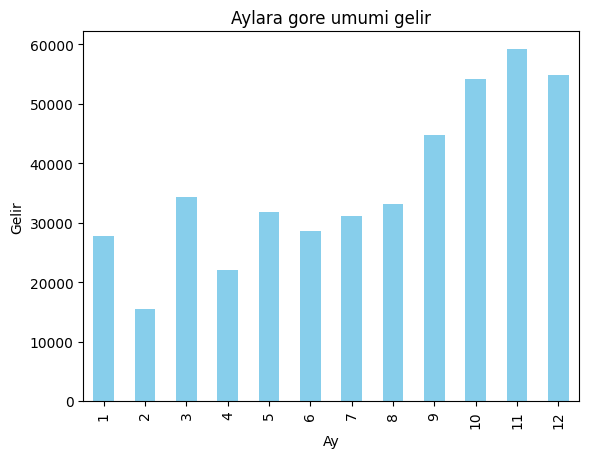

In [ ]:
df.groupby('invoice_month')['TotalPrice'].sum().plot(kind='bar', color='skyblue')
plt.title('Aylara gore umumi gelir')
plt.xlabel('Ay')
plt.ylabel('Gelir')
plt.show()

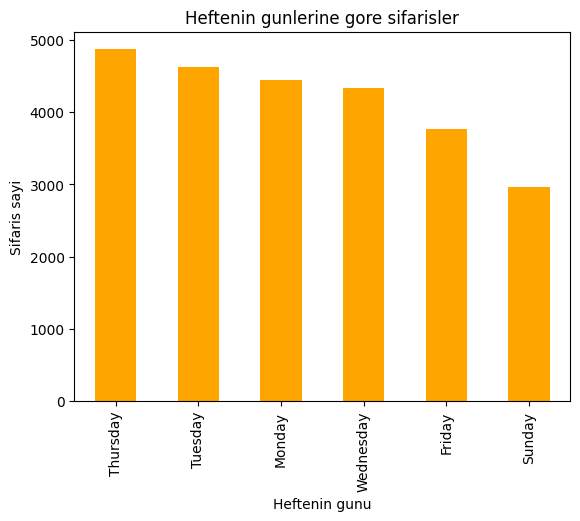

In [ ]:
df['invoice_weekday'].value_counts().plot(kind='bar', color='orange')
plt.title('Heftenin gunlerine gore sifarisler')
plt.xlabel('Heftenin gunu')
plt.ylabel('Sifaris sayi')
plt.show()

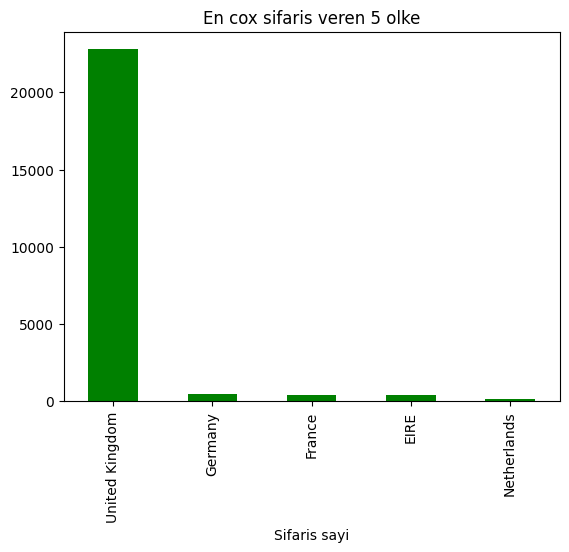

In [ ]:
df['Country'].value_counts().head().plot(kind='bar', color='green')
plt.title('En cox sifaris veren 5 olke')
plt.xlabel('Sifaris sayi')
plt.show()

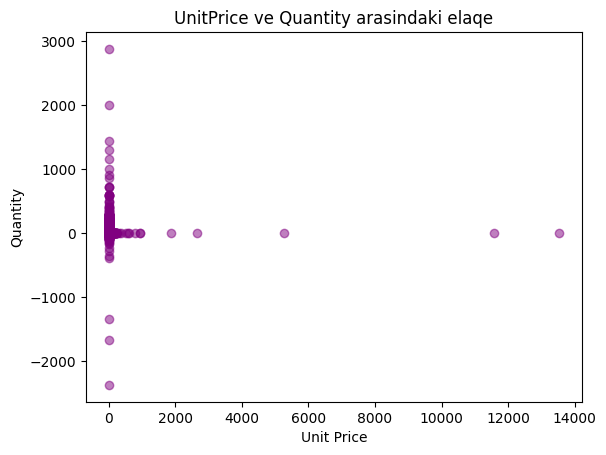

In [ ]:
plt.scatter(df['UnitPrice'], df['Quantity'], alpha=0.5, color='purple')
plt.title('UnitPrice ve Quantity arasindaki elaqe')
plt.xlabel('Unit Price')
plt.ylabel('Quantity')
plt.show()